# Small Portfolio Hedging: Neural Networks and Heston Benchmarks

### Overview:
We attempt to hedge a portfolio of 3 call options in a simulated Heston market with transaction costs. We compare paper-style networks trained on static stock paths generated prior to training with our networks trained on stock paths fresh batches generated in-line during training. We evaluate the CVaR and entropic risks for each model, and compare the trained strategies with classical Heston hedges. 

We also compare the time and memory complexity for training both the paper's and our model in order to describe use cases for either model.

# Comparison of Paper's and Our Network's Hedging Strategy Risk for a Small Portfolio

We hedge three European call options over 30 trading days in a simulated Heston market, where both stock price and variance change over time. The underlyings are assumed to be independent. 

The paper-style networks train from a fixed pool of paths. Our networks receive fresh simulated batches at each iteration. Validation selects the final policies, and 8,192 separate test paths measure their performance.

## Imports 

In [1]:
import importlib

from dataclasses import replace

from scripts.general_nn import generalNN
from scripts.settings import NetworkSettings, Settings, StockSettings, InstrumentSettings
from scripts.memory_tracker import run_memory_experiment
from scripts import plots

from pathlib import Path

from IPython.display import Markdown, display

## Define Synthetic Stock Parameters

In [2]:
stocks_list = [
    StockSettings(name="Stock1", initial_price=100.0, strike=100.0,
                  initial_variance=0.04, long_run_variance=0.04,
                  mean_reversion=1.0, vol_of_vol=2.0, correlation=-0.7),
    StockSettings(name="Stock2", initial_price=50.0, strike=50.0,
                  initial_variance=0.02, long_run_variance=0.02,
                  mean_reversion=1.2, vol_of_vol=1.8, correlation=-0.6),
    StockSettings(name="Stock3", initial_price=200.0, strike=200.0,
                  initial_variance=0.06, long_run_variance=0.06,
                  mean_reversion=0.8, vol_of_vol=2.2, correlation=-0.5),
]

## Model Setup

### General Settings

In [12]:
# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=500,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=50,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=2**17,
)

### Network Settings

In [13]:
n_stocks = len(stocks_list)

network = NetworkSettings(
    hidden_sizes=(12 * n_stocks, 12 * n_stocks),
    activation="tanh",
    batch_normalization=True
)

### Model Initialization

In [14]:
# dynamic_data:
# True: generate fresh training batches during each iteration.
# False: sample batches from one fixed training dataset.

settings = replace(settings, stocks=tuple(stocks_list), network=network)

# Create a new paper-style model that trades using stock and the variance information.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=False,
    name="Paper network: stock + variance",
)

# Create our new model using the same settings, including the same instruments from the paper example.
ours_settings = replace(
    settings,
    instruments=paper.settings.instruments
)
ours = generalNN(
    method="ours",
    settings=ours_settings,
    dynamic_data=True,
    name="Our network: stock + variance",
)

# Training and Evaluation

In [15]:
# Train and evaluate each newly created model.
for model in (paper, ours):

    print(f"\nTraining: {model.name}")

    # Prepare the training data and fit the hedging policies.
    model.train(verbose=True)

    # Measure the trained policies on separate test paths.
    model.evaluate()


Training: Paper network: stock + variance
paper_full_0_warmup: update 0, validation risk 17.94673
paper_full_0_warmup: update 100, validation risk 10.60519
paper_full_0_CVaR: update 0, validation risk 10.60648
paper_full_0_CVaR: update 500, validation risk 9.07401
paper_full_0_Entropic: update 0, validation risk 17.42041
paper_full_0_Entropic: update 500, validation risk 20.68700

Training: Our network: stock + variance
ours_0_warmup: update 0, validation risk 17.95961
ours_0_warmup: update 100, validation risk 10.52861
ours_0_CVaR: update 0, validation risk 10.53148
ours_0_CVaR: update 500, validation risk 9.07089
ours_0_Entropic: update 0, validation risk 22.35587
ours_0_Entropic: update 500, validation risk 18.98299


# Display Experiment Results

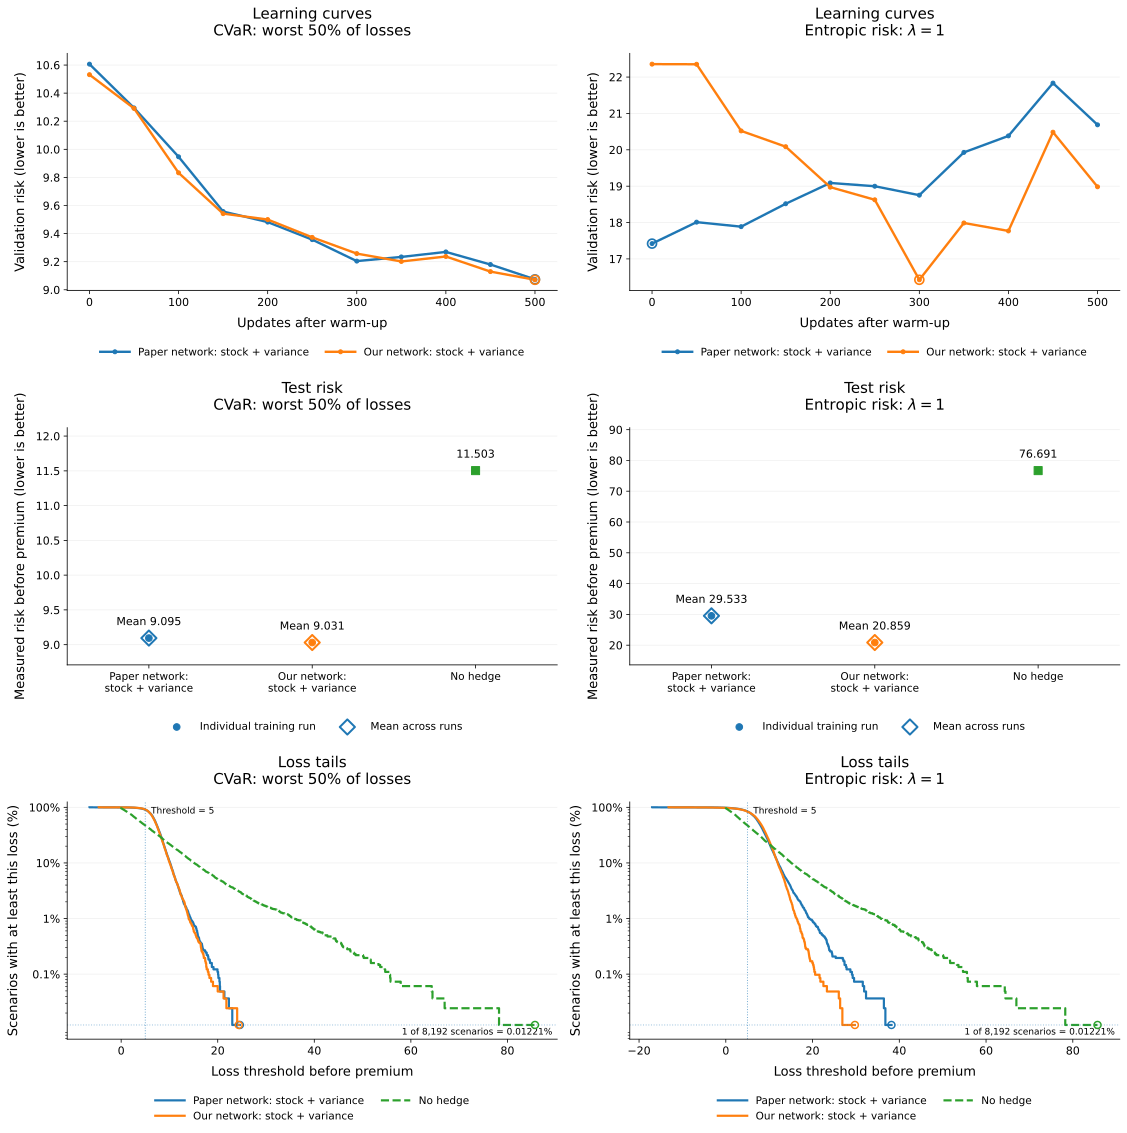

In [16]:
experiments = [paper, ours]

plots.plot_results_grid(experiments)

# Comparison of Paper's and Our Network's Hedging Runtime and Memory Complexity for a Small Portfolio

We use the same setup as in the risk comparison section.

## Model Setup

### General Settings

In [3]:
# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=500,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=50,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=2**17,
)

### Network Settings

In [4]:
n_stocks = len(stocks_list)

network = NetworkSettings(
    hidden_sizes=(12 * n_stocks, 12 * n_stocks),
    activation="tanh",
    batch_normalization=True
)

### Model Initialization

In [5]:
# dynamic_data:
# True: generate fresh training batches during each iteration.
# False: sample batches from one fixed training dataset.

settings = replace(settings, stocks=tuple(stocks_list), network=network)

# Create a new paper-style model that trades using stock and the variance information.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=False,
    name="Paper network: stock + variance",
)

# Create our new model using the same settings, including the same instruments from the paper example.
ours_settings = replace(
    settings,
    instruments=paper.settings.instruments
)
ours = generalNN(
    method="ours",
    settings=ours_settings,
    dynamic_data=True,
    name="Our network: stock + variance",
)

## Training and Memory/Time Tracking

In [ ]:
# Run one complete experiment at a time, each in a fresh process.
# Reports and logs remain available after the notebook kernel is restarted.
result_dir = Path("results/portfolio_memory_comparison")
reports = []

for model in (paper, ours):
    report = run_memory_experiment(model, output_dir=result_dir, verbose=True)
    reports.append(report)

fixed, fresh = reports

Running Paper network: stock + variance in a fresh process...
paper_full_0_warmup: update 0, validation risk 17.94673
paper_full_0_warmup: update 100, validation risk 10.60519
paper_full_0_CVaR: update 0, validation risk 10.60648
paper_full_0_CVaR: update 500, validation risk 9.07401
paper_full_0_Entropic: update 0, validation risk 17.42041
paper_full_0_Entropic: update 500, validation risk 20.68700
Paper network: stock + variance: baseline 289.6 MiB | sampled peak 1399.1 MiB | peak increase 1109.5 MiB | 97.0 s
Running Our network: stock + variance in a fresh process...
ours_0_warmup: update 0, validation risk 17.95961
ours_0_warmup: update 100, validation risk 10.52861
ours_0_CVaR: update 0, validation risk 10.53148
ours_0_CVaR: update 500, validation risk 9.07089
ours_0_Entropic: update 0, validation risk 22.35587
ours_0_Entropic: update 500, validation risk 18.98299
Our network: stock + variance: baseline 293.5 MiB | sampled peak 506.0 MiB | peak increase 212.4 MiB | 170.9 s


## Plot Peak Ram Usages and Timings

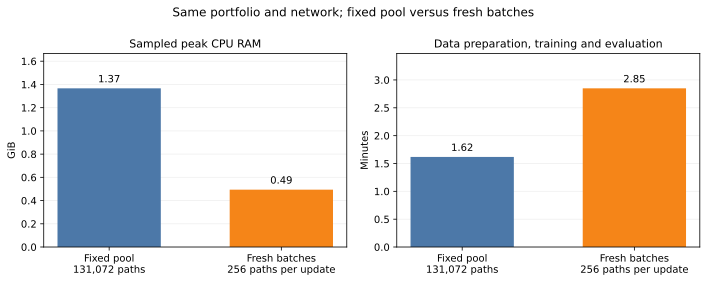

Fresh-batch training used **63.8% less sampled peak RAM** and took **76.2% more time** in this run. Test CVaR was **9.095** for the fixed pool and **9.031** for fresh batches. Test entropic risk was **29.533** and **20.859**, respectively.

In [9]:
plots.plot_memory_comparison(reports, save_dir=result_dir)

# Calculate the interpretation from this run rather than hard-coding results.
ram_change = 100 * (fresh["memory"]["peak_mib"] / fixed["memory"]["peak_mib"] - 1)
time_change = 100 * (fresh["memory"]["seconds"] / fixed["memory"]["seconds"] - 1)
ram_direction = "less" if ram_change < 0 else "more"
time_direction = "less" if time_change < 0 else "more"

display(Markdown(
    f"Fresh-batch training used **{abs(ram_change):.1f}% {ram_direction} sampled peak RAM** "
    f"and took **{abs(time_change):.1f}% {time_direction} time** in this run. "
    f"Test CVaR was **{fixed['test_risk']['CVaR']['mean']:.3f}** for the fixed pool "
    f"and **{fresh['test_risk']['CVaR']['mean']:.3f}** for fresh batches. "
    f"Test entropic risk was **{fixed['test_risk']['Entropic']['mean']:.3f}** "
    f"and **{fresh['test_risk']['Entropic']['mean']:.3f}**, respectively."
))

## More Memory and Timings Diagnostics

In [10]:
fixed, fresh = reports

# Refuse to compare different settings, test observations or implementation files.
for key in ("comparison_signature", "test_data_id", "instrument_data_ids", "source_hashes"):
    if fixed[key] != fresh[key]:
        raise ValueError(f"The two runs do not match: {key}")

# Each risk score uses the policy trained for that objective. Lower is better.
rows = [
    ("Sampled peak CPU RAM (GiB)", fixed["memory"]["peak_mib"] / 1024, fresh["memory"]["peak_mib"] / 1024, ".2f"),
    ("Retained datasets (MiB)", fixed["retained_dataset_mib"], fresh["retained_dataset_mib"], ".1f"),
    ("Data preparation + training + evaluation (minutes)", fixed["memory"]["seconds"] / 60, fresh["memory"]["seconds"] / 60, ".2f"),
    ("Parameters per policy", fixed["parameter_count"], fresh["parameter_count"], ",d"),
    ("Test CVaR", fixed["test_risk"]["CVaR"]["mean"], fresh["test_risk"]["CVaR"]["mean"], ".3f"),
    ("Test entropic risk", fixed["test_risk"]["Entropic"]["mean"], fresh["test_risk"]["Entropic"]["mean"], ".3f"),
]
table = "| Measurement | Fixed pool | Fresh batches |\n|---|---:|---:|\n"
table += "\n".join(f"| {label} | {left:{style}} | {right:{style}} |" for label, left, right, style in rows)
display(Markdown(table))

| Measurement | Fixed pool | Fresh batches |
|---|---:|---:|
| Sampled peak CPU RAM (GiB) | 1.37 | 0.49 |
| Retained datasets (MiB) | 622.1 | 69.1 |
| Data preparation + training + evaluation (minutes) | 1.62 | 2.85 |
| Parameters per policy | 64,980 | 64,980 |
| Test CVaR | 9.095 | 9.031 |
| Test entropic risk | 29.533 | 20.859 |